<a href="https://colab.research.google.com/github/Rani-Wheeza/wals-linguistic-association-analysis/blob/main/notebooks/01_wals_data_understanding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Exploring Linguistic Associations Using WALS

## Project Overview

This project investigates relationships between grammatical word-order patterns and tonal features across the world's languages using the World Atlas of Language Structures (WALS).

The analysis uses the Apriori association-rule mining algorithm to identify frequent combinations of linguistic features and evaluate the strength of these associations.

The project follows the CRISP-DM methodology.

## Research Question

What associations exist between grammatical word-order patterns and tonal features across the world's languages, and how do these associations vary across language families and geographical regions?

## Research Objectives

1. Identify the most frequent combinations of word-order patterns and tonal features.
2. Determine which associations are stronger than expected under independence using support, confidence and lift.
3. Compare the identified patterns across language families and geographical regions.


*Still deciding if i will impliment this. It will depend on if i have time towards the end*

### Supplementary Comparative Investigation

A supplementary case study will compare Bantu languages represented in Uganda and South Africa.

The investigation will examine similarities and differences in grammatical word-order patterns and tonal features using the same four linguistic variables selected from WALS.

The comparison will explore whether these linguistic characteristics remain similar across different geographical regions and branches of the Bantu language family.

The inclusion of individual languages will depend on their availability and completeness within the WALS dataset.


## Dataset

**Source:** World Atlas of Language Structures (WALS)

**Version:** v2020.6

**Download:** https://zenodo.org/records/23010827

The dataset was downloaded manually from Zenodo and extracted. Four CSV files were selected and uploaded to Google Colab:

- `values.csv` – Linguistic observations
- `languages.csv` – Language metadata
- `parameters.csv` – Linguistic feature definitions
- `codes.csv` – Feature category descriptions

The original CSV files will remain unchanged. Any cleaning and transformation will be performed using Python.


### Loading the Data

The WALS v2020.6 dataset was downloaded from Zenodo and the four required CSV files
(`values.csv`, `languages.csv`, `parameters.csv`, `codes.csv`) are uploaded manually to the
Colab session before running the notebook. Copies of the original files are also stored,
unchanged, in the repository's `data/raw/` folder.

To run this notebook: open the Files panel in Colab, upload the four CSV files from
`data/raw/`, then run all cells in order.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:

# Import pandas for working with tabular data
import os
import pandas as pd

# Incase no files are available or uploaded
required_files = ["values.csv", "languages.csv", "parameters.csv", "codes.csv"]

missing = [f for f in required_files if not os.path.exists(f)]
if missing:
    raise FileNotFoundError(
        f"Please upload these WALS files to Colab before running: {missing}"
    )

# Load the four original WALS CSV files
values = pd.read_csv("/content/values.csv")
languages = pd.read_csv("/content/languages.csv")
parameters = pd.read_csv("/content/parameters.csv")
codes = pd.read_csv("/content/codes.csv")

print("All four WALS datasets loaded successfully.")

All four WALS datasets loaded successfully.



## 2. Data Understanding

### 2.1 Dataset Dimensions

This section examines the number of rows and columns in each WALS dataset.

Understanding the dataset dimensions provides an initial overview of the amount of available data before selecting features and performing data preparation.


In [5]:
# Display the dimensions of each dataset

print("WALS Dataset Dimensions:")
print("-" * 35)
print("Values:", values.shape)
print("Languages:", languages.shape)
print("Parameters:", parameters.shape)
print("Codes:", codes.shape)

WALS Dataset Dimensions:
-----------------------------------
Values: (76475, 8)
Languages: (3573, 17)
Parameters: (192, 5)
Codes: (1143, 6)



### 2.2 Dataset Column Inspection

This section examines the column names in each dataset to understand the information available and identify the variables relevant to the research.

The inspection will help establish how linguistic observations can be connected to language metadata and feature definitions.


In [6]:

# Display column names for each dataset

datasets = {
    "Values": values,
    "Languages": languages,
    "Parameters": parameters,
    "Codes": codes
}

for name, dataset in datasets.items():
    print(f"\n{name} Dataset Columns")
    print("-" * 40)

    for column in dataset.columns:
        print(column)



Values Dataset Columns
----------------------------------------
ID
Language_ID
Parameter_ID
Value
Code_ID
Comment
Source
Example_ID

Languages Dataset Columns
----------------------------------------
ID
Name
Macroarea
Latitude
Longitude
Glottocode
ISO639P3code
Family
Subfamily
Genus
GenusIcon
ISO_codes
Samples_100
Samples_200
Country_ID
Source
Parent_ID

Parameters Dataset Columns
----------------------------------------
ID
Name
Description
ColumnSpec
Chapter_ID

Codes Dataset Columns
----------------------------------------
ID
Parameter_ID
Name
Description
Number
icon



### 2.3 Initial Data Inspection

This section examines the first few records from each dataset.

The purpose is to understand how linguistic observations, language metadata, feature definitions and category descriptions are represented in the original WALS data.


In [7]:

# Display the first five records from each dataset

print("VALUES DATASET")
display(values.head())

print("LANGUAGES DATASET")
display(languages.head())

print("PARAMETERS DATASET")
display(parameters.head())

print("CODES DATASET")
display(codes.head())


VALUES DATASET


,ID,Language_ID,Parameter_ID,Value,Code_ID,Comment,Source,Example_ID
0,81A-aab,aab,81A,2,81A-2,NaN,Nekitel-1985[94],NaN
1,82A-aab,aab,82A,1,82A-1,NaN,Nekitel-1985[94],NaN
2,83A-aab,aab,83A,2,83A-2,NaN,Nekitel-1985[94],NaN
3,87A-aab,aab,87A,2,87A-2,NaN,Nekitel-1985[95],NaN
4,88A-aab,aab,88A,2,88A-2,NaN,Nekitel-1985[95],NaN


LANGUAGES DATASET


,ID,Name,Macroarea,Latitude,Longitude,Glottocode,ISO639P3code,Family,Subfamily,Genus,GenusIcon,ISO_codes,Samples_100,Samples_200,Country_ID,Source,Parent_ID
0,aab,Arapesh (Abu),Papunesia,-3.450000,142.950000,abua1245,aah,Torricelli,NaN,Kombio-Arapesh,NaN,aah,False,False,PG,Nekitel-1985,genus-kombioarapesh
1,aar,Aari,Africa,6.000000,36.583333,aari1239,aiw,Afro-Asiatic,Omotic,South Omotic,NaN,aiw,False,False,ET,Hayward-1990a,genus-southomotic
2,aba,Abau,Papunesia,-4.000000,141.250000,abau1245,aau,Sepik,NaN,Abau,NaN,aau,False,False,PG,Bailey-1975,genus-abau
3,abb,Arabic (Chadian),Africa,13.833333,20.833333,chad1249,shu,Afro-Asiatic,NaN,Semitic,NaN,shu,False,False,TD,Abu-Absi-1995,genus-semitic
4,abd,Abidji,Africa,5.666667,-4.583333,abid1235,abi,Niger-Congo,Kwa,Agneby,NaN,abi,False,False,CI,NaN,genus-agneby


PARAMETERS DATASET


,ID,Name,Description,ColumnSpec,Chapter_ID
0,1A,Consonant Inventories,NaN,NaN,1
1,2A,Vowel Quality Inventories,NaN,NaN,2
2,3A,Consonant-Vowel Ratio,NaN,NaN,3
3,4A,Voicing in Plosives and Fricatives,NaN,NaN,4
4,5A,Voicing and Gaps in Plosive Systems,NaN,NaN,5


CODES DATASET


,ID,Parameter_ID,Name,Description,Number,icon
0,1A-1,1A,Small,Small,1,c0000dd
1,1A-2,1A,Moderately small,Moderately small,2,c9999ff
2,1A-3,1A,Average,Average,3,cffffff
3,1A-4,1A,Moderately large,Moderately large,4,cff66ff
4,1A-5,1A,Large,Large,5,cdd0000



### 2.4 Understanding Feature Definitions and Categories

This section examines the selected linguistic feature definitions and their associated categories.

The purpose is to understand how WALS represents the different linguistic patterns and how numerical values correspond to meaningful category descriptions.


In [8]:

# Display our four selected linguistic features

selected_features = ["81A", "13A", "85A", "87A"]

print("SELECTED FEATURE DEFINITIONS")
display(
    parameters[
        parameters["ID"].isin(selected_features)
    ]
)

# Display the possible categories for these features

print("SELECTED FEATURE CATEGORIES")
display(
    codes[
        codes["Parameter_ID"].isin(selected_features)
    ].sort_values(["Parameter_ID", "Number"])
)


SELECTED FEATURE DEFINITIONS


,ID,Name,Description,ColumnSpec,Chapter_ID
13,13A,Tone,NaN,NaN,13
86,81A,"Order of Subject, Object and Verb",NaN,NaN,81
91,85A,Order of Adposition and Noun Phrase,NaN,NaN,85
93,87A,Order of Adjective and Noun,NaN,NaN,87


SELECTED FEATURE CATEGORIES


,ID,Parameter_ID,Name,Description,Number,icon
56,13A-1,13A,No tones,No tones,1,cffffff
57,13A-2,13A,Simple tone system,Simple tone system,2,cff66ff
58,13A-3,13A,Complex tone system,Complex tone system,3,cdd0000
404,81A-1,81A,SOV,Subject-object-verb (SOV),1,c0000dd
405,81A-2,81A,SVO,Subject-verb-object (SVO),2,cdd0000
406,81A-3,81A,VSO,Verb-subject-object (VSO),3,cffff00
407,81A-4,81A,VOS,Verb-object-subject (VOS),4,dffff00
408,81A-5,81A,OVS,Object-verb-subject (OVS),5,ddd0000
409,81A-6,81A,OSV,Object-subject-verb (OSV),6,d0000dd
410,81A-7,81A,No dominant order,Lacking a dominant word order,7,ccccccc


The four selected WALS features represent different grammatical and tonal characteristics of languages. Before analysing the data, it is important to understand the categories available for each feature.

The following code displays the category codes, names and descriptions associated with each selected feature. This helps identify what each category represents and how WALS classifies the different linguistic characteristics. Understanding these categories will be important when preparing the data for association rule mining.

In [9]:
# Display the available categories for each selected WALS feature

for feature in selected_features:

    # Retrieve the name of the current feature
    feature_name = parameters.loc[
        parameters["ID"] == feature, "Name"
    ].iloc[0]

    print("\n" + "=" * 60)
    print(f"FEATURE: {feature} - {feature_name}")
    print("=" * 60)

    # Retrieve and display the categories associated with the feature
    feature_codes = codes[
        codes["Parameter_ID"] == feature
    ][["ID", "Name", "Description", "Number"]]

    display(feature_codes.sort_values("Number"))


FEATURE: 81A - Order of Subject, Object and Verb


,ID,Name,Description,Number
404,81A-1,SOV,Subject-object-verb (SOV),1
405,81A-2,SVO,Subject-verb-object (SVO),2
406,81A-3,VSO,Verb-subject-object (VSO),3
407,81A-4,VOS,Verb-object-subject (VOS),4
408,81A-5,OVS,Object-verb-subject (OVS),5
409,81A-6,OSV,Object-subject-verb (OSV),6
410,81A-7,No dominant order,Lacking a dominant word order,7



FEATURE: 13A - Tone


,ID,Name,Description,Number
56,13A-1,No tones,No tones,1
57,13A-2,Simple tone system,Simple tone system,2
58,13A-3,Complex tone system,Complex tone system,3



FEATURE: 85A - Order of Adposition and Noun Phrase


,ID,Name,Description,Number
428,85A-1,Postpositions,Postpositions,1
429,85A-2,Prepositions,Prepositions,2
430,85A-3,Inpositions,Inpositions,3
431,85A-4,No dominant order,More than one adposition type with none dominant,4
432,85A-5,No adpositions,No adpositions,5



FEATURE: 87A - Order of Adjective and Noun


,ID,Name,Description,Number
436,87A-1,Adjective-Noun,Modifying adjective precedes noun (AdjN),1
437,87A-2,Noun-Adjective,Modifying adjective follows noun (NAdj),2
438,87A-3,No dominant order,Both orders of noun and modifying adjective oc...,3
439,87A-4,Only internally-headed relative clauses,"Adjectives do not modify nouns, occurring as p...",4


### Interpretation of Selected Feature Categories

The inspection of the WALS feature definitions and category codes identified the possible grammatical and tonal classifications available for the four selected features.

- **81A – Order of Subject, Object and Verb:** Identifies the dominant arrangement of subjects, objects and verbs within a sentence.
- **13A – Tone:** Classifies languages according to whether they have no tones, a simple tone system or a complex tone system.
- **85A – Order of Adposition and Noun Phrase:** Identifies the position of adpositions in relation to noun phrases.
- **87A – Order of Adjective and Noun:** Identifies whether adjectives generally precede or follow the nouns they modify.

These features provide categorical data that can be examined for associations across languages. Understanding their available categories is necessary before preparing the dataset for association rule mining.

The next stage will involve examining data quality, missing values and the availability of observations for each selected feature.

### 2.5 Initial Data Quality Assessment

Before preparing the data for analysis, an initial data quality assessment is required to identify missing values in the datasets.

This step examines the completeness of the four WALS tables to determine whether important information is missing. Identifying missing values early will help guide decisions about data cleaning and ensure that incomplete observations are handled appropriately.

###Missing-value assessment
The following code checks each WALS dataset for missing values. It calculates the number and percentage of missing entries in every column. This will help identify incomplete information that may need to be addressed during data preparation.


In [10]:
# Check the number and percentage of missing values in each dataset

for name, dataset in datasets.items():

    print(f"\n{name} Dataset - Missing Values")
    print("-" * 50)

    missing_summary = pd.DataFrame({
        "Missing Values": dataset.isnull().sum(),
        "Missing Percentage (%)": (
            dataset.isnull().mean() * 100
        ).round(2)
    })

    display(missing_summary)


Values Dataset - Missing Values
--------------------------------------------------


,Missing Values,Missing Percentage (%)
ID,0,0.00
Language_ID,74,0.10
Parameter_ID,0,0.00
Value,0,0.00
Code_ID,0,0.00
Comment,74102,96.90
Source,7092,9.27
Example_ID,74863,97.89



Languages Dataset - Missing Values
--------------------------------------------------


,Missing Values,Missing Percentage (%)
ID,1,0.03
Name,0,0.00
Macroarea,911,25.50
Latitude,911,25.50
Longitude,911,25.50
Glottocode,928,25.97
ISO639P3code,960,26.87
Family,911,25.50
Subfamily,2662,74.50
Genus,911,25.50



Parameters Dataset - Missing Values
--------------------------------------------------


,Missing Values,Missing Percentage (%)
ID,0,0.0
Name,0,0.0
Description,192,100.0
ColumnSpec,192,100.0
Chapter_ID,0,0.0



Codes Dataset - Missing Values
--------------------------------------------------


,Missing Values,Missing Percentage (%)
ID,0,0.00
Parameter_ID,0,0.00
Name,16,1.40
Description,4,0.35
Number,0,0.00
icon,0,0.00


### Initial Missing-Value Findings

The missing-value assessment identified incomplete information across the four WALS datasets.

The Values dataset contains 74 observations with missing Language_ID values. The Languages dataset also contains missing information in several geographical and linguistic classification fields.

Further investigation is required to distinguish individual language records from classification entries and determine whether missing identifiers affect the four selected features.

Some supplementary fields, such as comments, examples and descriptions, also contain missing values. These fields are not essential to the planned association rule analysis.

### Identifying Individual Language Records

The WALS Languages dataset contains both individual language records and linguistic classification entries. Classification entries represent language families, subfamilies and genera rather than individual languages.

These entries can be identified by prefixes in their IDs, such as `family-`, `subfamily-` and `genus-`.

The following code identifies and counts these classification entries to establish how many individual language records are available for analysis.

In [11]:
# Identify and count linguistic classification records

classification_prefixes = (
    "family-",
    "subfamily-",
    "genus-"
)

is_classification = languages["ID"].str.startswith(
    classification_prefixes,
    na=False
)

print("Total records:", len(languages))
print("Classification records:", is_classification.sum())
print("Individual language records:", (~is_classification).sum())

Total records: 3573
Classification records: 911
Individual language records: 2662


The Languages dataset contains 3,573 records, of which 911 are linguistic classification entries and 2,662 are individual language records.

The classification entries are not individual languages and will not form part of the language-level analysis. The individual language records will be used as the basis for further data preparation.

### Assessing Individual Language Metadata

After distinguishing classification entries from individual languages, the remaining records are examined for missing information in fields relevant to the project.

Particular attention is given to language identifiers, geographical macroareas, language families, subfamilies and country associations. These fields will support the identification and comparison of languages across linguistic families and geographical regions.

In [12]:
# Create a dataset containing individual language records

individual_languages = languages.loc[
    ~is_classification
].copy()

print("Individual language records:", len(individual_languages))

# Check missing values in relevant metadata fields

relevant_columns = [
    "ID",
    "Macroarea",
    "Family",
    "Subfamily",
    "Country_ID"
]

display(
    pd.DataFrame({
        "Missing Values": individual_languages[relevant_columns].isnull().sum(),
        "Missing Percentage (%)": (
            individual_languages[relevant_columns].isnull().mean() * 100
        ).round(2)
    })
)

Individual language records: 2662


,Missing Values,Missing Percentage (%)
ID,1,0.04
Macroarea,0,0.00
Family,0,0.00
Subfamily,1751,65.78
Country_ID,10,0.38


The 2,662 individual language records contain complete Macroarea and Family information, supporting the planned geographical and language-family comparisons.

However, some records have missing subfamily classifications, and ten records lack Country_ID information. One record, Nandi, also has a missing language identifier. These limitations will be considered during data preparation, depending on the requirements of each analysis.

### Missing Language Identifiers in Selected Features

The Values dataset contains 74 observations with missing Language_ID values. Since Language_ID is required to connect feature observations with individual language records, these observations may affect the analysis.

The following check focuses on the four selected features to identify how many observations have missing language identifiers.

In [13]:
# Identify missing Language_ID values affecting selected features

missing_value_languages = values[
    values["Language_ID"].isnull()
]

selected_missing = missing_value_languages[
    missing_value_languages["Parameter_ID"].isin(selected_features)
]

print("Total observations with missing Language_ID:",
      len(missing_value_languages))

print("Missing Language_ID observations in selected features:",
      len(selected_missing))

display(
    selected_missing[
        ["ID", "Language_ID", "Parameter_ID", "Value", "Code_ID"]
    ]
)

Total observations with missing Language_ID: 74
Missing Language_ID observations in selected features: 4


,ID,Language_ID,Parameter_ID,Value,Code_ID
47648,13A-nan,NaN,13A,2,13A-2
47675,81A-nan,NaN,81A,3,81A-3
47679,85A-nan,NaN,85A,2,85A-2
47681,87A-nan,NaN,87A,2,87A-2


The investigation identified four observations with missing Language_ID values among the selected features, with one affected observation per feature.

Although these observations contain recorded feature categories, they cannot be reliably associated with individual languages. Their treatment will therefore be addressed during Data Preparation.

### Duplicate Observation Assessment

Before combining the selected linguistic features, it is necessary to check for duplicate observations.

Each individual language should ideally have only one recorded category for each selected feature. Multiple observations for the same language-feature combination could create inconsistencies when preparing the data for association rule mining.

The following code identifies repeated combinations of Language_ID and Parameter_ID among observations with a recorded language identifier.

In [14]:
# Check for duplicate language-feature combinations

selected_values = values[
    (values["Parameter_ID"].isin(selected_features)) &
    (values["Language_ID"].notna())
].copy()

duplicate_observations = selected_values[
    selected_values.duplicated(
        subset=["Language_ID", "Parameter_ID"],
        keep=False
    )
].sort_values(["Language_ID", "Parameter_ID"])

print("Number of duplicate observations:",
      len(duplicate_observations))

display(duplicate_observations)

Number of duplicate observations: 0


,ID,Language_ID,Parameter_ID,Value,Code_ID,Comment,Source,Example_ID


The duplicate assessment found no repeated language-feature combinations among observations with recorded Language_ID values. This indicates that each observed language-feature combination has a single recorded entry in the selected data, allowing the dataset to proceed to further preparation.

### Selected Feature Data Coverage

The final check examines the availability of observations for each of the four selected linguistic features.

It calculates the number of individual languages with recorded data for each feature and identifies how many languages have complete observations across all four features.

This is important because association rule mining requires observations containing the selected feature combinations. The results will help determine the amount of data available for the analysis before data preparation begins.

In [15]:
# Calculate the number of language observations available for each feature

feature_coverage = (
    selected_values.groupby("Parameter_ID")["Language_ID"]
    .nunique()
    .reindex(selected_features, fill_value=0)
    .reset_index()
)

feature_coverage.columns = [
    "Feature",
    "Languages with Recorded Observations"
]

print("Language Coverage by Selected Feature:")
display(feature_coverage)


# Identify languages with observations for all four selected features

feature_matrix = selected_values.pivot(
    index="Language_ID",
    columns="Parameter_ID",
    values="Value"
)

complete_languages = feature_matrix.dropna(
    subset=selected_features
)

print("Languages with at least one selected feature:",
      len(feature_matrix))

print("Languages with complete observations across all four features:",
      len(complete_languages))

print("Languages missing at least one selected feature:",
      len(feature_matrix) - len(complete_languages))

Language Coverage by Selected Feature:


,Feature,Languages with Recorded Observations
0,81A,1375
1,13A,526
2,85A,1183
3,87A,1366


Languages with at least one selected feature: 1719
Languages with complete observations across all four features: 304
Languages missing at least one selected feature: 1415


### Interpretation of Feature Coverage

The coverage assessment shows that the four selected WALS features have different levels of data availability. Feature 81A has the highest number of recorded observations (1,375), while Feature 13A (Tone) has the lowest (526).

Out of 1,719 languages with at least one selected feature recorded, 304 have complete observations across all four features. The remaining 1,415 languages are missing at least one of the selected features.

This difference in coverage is important for the analysis. Using only languages with complete observations across all four features would reduce the available sample to 304 languages. This may affect how representative the results are of the world's languages.

During Data Preparation, the approach to missing feature observations will be considered carefully to balance data completeness and the amount of information retained.

### 3.1 Selecting the Relevant Linguistic Features

The original WALS Values dataset contains observations for 192 linguistic features. However, this research focuses on four selected features: 81A, 13A, 85A and 87A.

The first preparation step filters the Values dataset to retain only observations belonging to these four features.

Observations with missing Language_ID values are excluded because they cannot be reliably connected to individual language records in the Languages dataset. The original dataset remains unchanged, and all preparation is performed on a separate working copy.

In [16]:
# Select observations belonging to the four research features

prepared_values = values[
    values["Parameter_ID"].isin(selected_features)
].copy()

print("Selected feature observations:",
      len(prepared_values))


# Identify and exclude observations with missing Language_ID

missing_ids = prepared_values["Language_ID"].isnull().sum()

prepared_values = prepared_values[
    prepared_values["Language_ID"].notna()
].copy()

print("Observations excluded due to missing Language_ID:",
      missing_ids)

print("Remaining observations:",
      len(prepared_values))

print("\nObservations per selected feature:")
display(
    prepared_values["Parameter_ID"].value_counts().sort_index()
)

Selected feature observations: 4454
Observations excluded due to missing Language_ID: 4
Remaining observations: 4450

Observations per selected feature:


,count
Parameter_ID,
13A,526
81A,1375
85A,1183
87A,1366


### Interpretation of Feature Selection

The filtering process identified 4,454 observations belonging to the four selected linguistic features.

Four observations had missing Language_ID values and were excluded because they could not be linked to individual language records. This left 4,450 observations for further preparation.

The remaining observations retain the same feature counts identified during Data Understanding, confirming that the filtering process has preserved the available data for the selected features.

The original WALS Values dataset remains unchanged.

### 3.2 Joining Language Metadata

The selected linguistic observations need to be connected to the Languages dataset to provide additional information about each language.

The datasets will be joined using the language identifier:
- `Language_ID` in the Values dataset.
- `ID` in the Languages dataset.

Relevant metadata, including language name, macroarea, family, subfamily, genus and country, will be included.

A left join will be used to preserve all selected linguistic observations while checking whether each observation has a matching language record.

In [17]:
# Select the language metadata required for the analysis

language_metadata = individual_languages.loc[
    individual_languages["ID"].notna(),
    [
        "ID",
        "Name",
        "Macroarea",
        "Family",
        "Subfamily",
        "Genus",
        "Country_ID"
    ]
].copy()

# Rename ID so it matches Language_ID in the Values dataset

language_metadata = language_metadata.rename(
    columns={"ID": "Language_ID"}
)


# Join linguistic observations with language metadata

prepared_data = prepared_values.merge(
    language_metadata,
    on="Language_ID",
    how="left",
    validate="many_to_one",
    indicator=True
)


# Check the join results

matched = (prepared_data["_merge"] == "both").sum()
unmatched = (prepared_data["_merge"] == "left_only").sum()

print("Total observations:", len(prepared_data))
print("Successfully matched observations:", matched)
print("Observations without matching language metadata:", unmatched)

print("\nJoin status:")
display(prepared_data["_merge"].value_counts())

print("\nPreview of the joined dataset:")
display(prepared_data.head())

Total observations: 4450
Successfully matched observations: 4450
Observations without matching language metadata: 0

Join status:


,count
_merge,
both,4450
left_only,0
right_only,0



Preview of the joined dataset:


,ID,Language_ID,Parameter_ID,Value,Code_ID,Comment,Source,Example_ID,Name,Macroarea,Family,Subfamily,Genus,Country_ID,_merge
0,81A-aab,aab,81A,2,81A-2,NaN,Nekitel-1985[94],NaN,Arapesh (Abu),Papunesia,Torricelli,NaN,Kombio-Arapesh,PG,both
1,87A-aab,aab,87A,2,87A-2,NaN,Nekitel-1985[95],NaN,Arapesh (Abu),Papunesia,Torricelli,NaN,Kombio-Arapesh,PG,both
2,85A-aar,aar,85A,1,85A-1,NaN,Hayward-1990a[489-490],NaN,Aari,Africa,Afro-Asiatic,Omotic,South Omotic,ET,both
3,87A-aar,aar,87A,2,87A-2,NaN,Hayward-1990a[460-461],NaN,Aari,Africa,Afro-Asiatic,Omotic,South Omotic,ET,both
4,81A-aba,aba,81A,1,81A-1,NaN,Bailey-1975[passim],NaN,Abau,Papunesia,Sepik,NaN,Abau,PG,both


### Interpretation of the Metadata Join

The left join successfully matched all 4,450 selected linguistic observations with their corresponding language metadata records.

No unmatched observations were identified. This confirms that the selected observations can be connected to the Languages dataset using Language_ID.

The joined dataset now contains the linguistic observations alongside relevant information about each language, including its name, geographical macroarea, language family, genus and country.

The successful join provides a foundation for the geographical and language-family comparisons planned in this research.

### 3.3 Mapping Feature Categories

The selected linguistic observations contain numerical values and category identifiers rather than fully descriptive category names.

The WALS Codes dataset provides the descriptions associated with these categories.

The Code_ID column in the prepared dataset will be matched with the ID column in codes.csv. This will allow each observation to be associated with its corresponding category name and description.

A left join will preserve all observations while allowing unmatched category identifiers to be identified and investigated.

In [22]:
# Select the relevant category information from the Codes dataset

feature_codes = codes[
    [
        "ID",
        "Parameter_ID",
        "Name",
        "Description"
    ]
].copy()

# Rename columns for clarity

feature_codes = feature_codes.rename(
    columns={
        "ID": "Code_ID",
        "Name": "Category_Name",
        "Description": "Category_Description"
    }
)


# Remove columns from any previous category-mapping attempt

prepared_data = prepared_data.drop(
    columns=[
        "category_match",
        "Category_Name",
        "Category_Description"
    ],
    errors="ignore"
)


# Join category information to the prepared dataset

prepared_data = prepared_data.merge(
    feature_codes,
    on="Code_ID",
    how="left",
    validate="many_to_one",
    indicator="category_match"
)


# Check the category mapping results

matched_categories = (
    prepared_data["category_match"] == "both"
).sum()

unmatched_categories = (
    prepared_data["category_match"] == "left_only"
).sum()

print("Total observations:", len(prepared_data))
print("Successfully mapped categories:", matched_categories)
print("Unmatched categories:", unmatched_categories)

print("\nPreview of mapped categories:")

display(
    prepared_data[
        [
            "Language_ID",
            "Name",
            "Parameter_ID",
            "Value",
            "Code_ID",
            "Category_Name",
            "Category_Description"
        ]
    ].head(10)
)

Total observations: 4450
Successfully mapped categories: 4450
Unmatched categories: 0

Preview of mapped categories:


,Language_ID,Name,Parameter_ID,Value,Code_ID,Category_Name,Category_Description
0,aab,Arapesh (Abu),81A,2,81A-2,SVO,Subject-verb-object (SVO)
1,aab,Arapesh (Abu),87A,2,87A-2,Noun-Adjective,Modifying adjective follows noun (NAdj)
2,aar,Aari,85A,1,85A-1,Postpositions,Postpositions
3,aar,Aari,87A,2,87A-2,Noun-Adjective,Modifying adjective follows noun (NAdj)
4,aba,Abau,81A,1,81A-1,SOV,Subject-object-verb (SOV)
5,aba,Abau,85A,1,85A-1,Postpositions,Postpositions
6,abi,Abipón,81A,2,81A-2,SVO,Subject-verb-object (SVO)
7,abi,Abipón,85A,2,85A-2,Prepositions,Prepositions
8,abi,Abipón,87A,3,87A-3,No dominant order,Both orders of noun and modifying adjective oc...
9,abk,Abkhaz,13A,1,13A-1,No tones,No tones


### Interpretation of Feature Category Mapping

The category mapping successfully matched all 4,450 linguistic observations with their corresponding entries in the WALS Codes dataset.

No unmatched category identifiers were found.

The numerical feature categories have now been supplemented with readable category names and descriptions. For example, numerical codes for word order have been translated into categories such as SOV and SVO.

This makes the dataset easier to interpret and provides meaningful categorical values for the subsequent association rule mining process.

### 3.4 Reshaping the Dataset

The prepared dataset currently uses a long format, where each row represents an observation for one linguistic feature belonging to a particular language.

Association rule mining requires the selected features to be represented together for each language.

The dataset will therefore be transformed into a wide format using a pivot operation:

- Each row will represent an individual language.
- Each column will represent one of the four selected WALS features.
- Each cell will contain the corresponding linguistic category.

Missing observations will remain as missing values rather than being assigned an artificial category. Their treatment will be considered in a later preparation step.

In [23]:
# Reshape the dataset from long format to wide format

feature_matrix = prepared_data.pivot(
    index="Language_ID",
    columns="Parameter_ID",
    values="Category_Name"
)

# Keep the selected features in the intended order

feature_matrix = feature_matrix.reindex(
    columns=selected_features
)

# Check the reshaped dataset

print("Reshaped dataset dimensions:", feature_matrix.shape)

print("\nNumber of available observations per feature:")
display(feature_matrix.notna().sum())

print("\nPreview of the reshaped dataset:")
display(feature_matrix.head(10))

Reshaped dataset dimensions: (1719, 4)

Number of available observations per feature:


,0
Parameter_ID,
81A,1375
13A,526
85A,1183
87A,1366



Preview of the reshaped dataset:


Parameter_ID,81A,13A,85A,87A
Language_ID,,,,
aab,SVO,NaN,NaN,Noun-Adjective
aar,NaN,NaN,Postpositions,Noun-Adjective
aba,SOV,NaN,Postpositions,NaN
abi,SVO,NaN,Prepositions,No dominant order
abk,SOV,No tones,Postpositions,Noun-Adjective
abn,SOV,NaN,NaN,Noun-Adjective
abo,SOV,NaN,NaN,Noun-Adjective
abu,SVO,NaN,Prepositions,Noun-Adjective
abv,SOV,NaN,No adpositions,Noun-Adjective


### Interpretation of Dataset Reshaping

The pivot operation successfully transformed the prepared dataset from long format into wide format.

The resulting feature matrix contains 1,719 individual language records and four columns representing the selected WALS features: 81A, 13A, 85A and 87A.

The number of available observations for each feature remains consistent with the earlier Data Understanding assessment.

Missing values have been preserved as NaN rather than being assigned artificial categories. Only 304 languages currently have complete observations across all four features.

The reshaped dataset provides the required structure for examining combinations of linguistic characteristics.

### 3.5 Assessing Missing Feature Observations

The reshaped dataset contains missing observations across the four selected linguistic features.

Removing every language with at least one missing feature would reduce the dataset to 304 complete language records.

However, the main research question focuses on associations between grammatical word order and tonal features. Therefore, languages with observations for these two features may still be useful even when other selected features are missing.

This section compares the available language counts for different feature combinations to support an evidence-based decision about the dataset used for association rule mining.

In [24]:
# Compare language coverage for different feature combinations

feature_combinations = {
    "Word Order and Tone": ["81A", "13A"],
    "Word Order and Adposition Order": ["81A", "85A"],
    "Word Order and Adjective Order": ["81A", "87A"],
    "Tone and Adposition Order": ["13A", "85A"],
    "Tone and Adjective Order": ["13A", "87A"],
    "All Four Features": ["81A", "13A", "85A", "87A"]
}

coverage_results = []

for combination, features in feature_combinations.items():

    available_languages = feature_matrix[features].dropna()

    coverage_results.append({
        "Feature Combination": combination,
        "Number of Languages": len(available_languages)
    })

coverage_summary = pd.DataFrame(coverage_results)

display(coverage_summary)

,Feature Combination,Number of Languages
0,Word Order and Tone,372
1,Word Order and Adposition Order,1027
2,Word Order and Adjective Order,1181
3,Tone and Adposition Order,345
4,Tone and Adjective Order,367
5,All Four Features,304


### Interpretation of Feature Combination Coverage

The coverage assessment shows that the number of available languages varies depending on the selected feature combination.

The primary comparison between word order (81A) and tone (13A) has 372 languages with observations for both features. This provides a larger sample than restricting the analysis to the 304 languages with complete observations across all four features.

Comparisons involving tone have lower coverage because Feature 13A has fewer recorded observations than the other selected features.

These findings support using separate datasets for different stages of the analysis:

- The primary word-order and tone investigation will use languages with observations for both features.
- The broader four-feature investigation will use languages with complete observations across all four features.

This approach retains more data for the main research question while ensuring that missing observations are not incorrectly treated as linguistic categories.

### 3.6 Preparing the Analysis Datasets

Based on the feature coverage assessment, two datasets will be prepared for the analysis.

**Primary analysis dataset:** Contains languages with recorded observations for both Feature 81A (Order of Subject, Object and Verb) and Feature 13A (Tone).

**Broader analysis dataset:** Contains languages with complete observations across all four selected features.

The relevant language metadata will also be retained to support comparisons across language families and geographical regions.

Both datasets will be created separately, leaving the original prepared feature matrix unchanged.

In [25]:
# Create the primary dataset using word order and tone

primary_analysis = (
    feature_matrix
    .dropna(subset=["81A", "13A"])
    .copy()
    .reset_index()
)


# Create the broader dataset using all four features

broader_analysis = (
    feature_matrix
    .dropna(subset=selected_features)
    .copy()
    .reset_index()
)


# Select one metadata record per language

language_info = prepared_data[
    [
        "Language_ID",
        "Name",
        "Macroarea",
        "Family",
        "Subfamily",
        "Genus",
        "Country_ID"
    ]
].drop_duplicates(subset="Language_ID")


# Add language metadata to both analysis datasets

primary_analysis = primary_analysis.merge(
    language_info,
    on="Language_ID",
    how="left",
    validate="one_to_one"
)

broader_analysis = broader_analysis.merge(
    language_info,
    on="Language_ID",
    how="left",
    validate="one_to_one"
)


# Display dataset dimensions

print("Primary analysis dataset:", primary_analysis.shape)
print("Broader analysis dataset:", broader_analysis.shape)

print("\nPrimary analysis preview:")
display(primary_analysis.head())

print("\nBroader analysis preview:")
display(broader_analysis.head())

Primary analysis dataset: (372, 11)
Broader analysis dataset: (304, 11)

Primary analysis preview:


,Language_ID,81A,13A,85A,87A,Name,Macroarea,Family,Subfamily,Genus,Country_ID
0,abk,SOV,No tones,Postpositions,Noun-Adjective,Abkhaz,Eurasia,Northwest Caucasian,NaN,Northwest Caucasian,GE
1,acm,SVO,Simple tone system,Prepositions,NaN,Achumawi,North America,Hokan,Palaihnihan,Achumawi,US
2,aco,No dominant order,Complex tone system,Postpositions,No dominant order,Acoma,North America,Keresan,NaN,Keresan,US
3,aeg,SVO,No tones,Prepositions,Noun-Adjective,Arabic (Egyptian),Africa,Afro-Asiatic,NaN,Semitic,EG
4,agh,SVO,Simple tone system,NaN,Noun-Adjective,Aghem,Africa,Niger-Congo,Benue-Congo,Wide Grassfields,CM



Broader analysis preview:


,Language_ID,81A,13A,85A,87A,Name,Macroarea,Family,Subfamily,Genus,Country_ID
0,abk,SOV,No tones,Postpositions,Noun-Adjective,Abkhaz,Eurasia,Northwest Caucasian,NaN,Northwest Caucasian,GE
1,aco,No dominant order,Complex tone system,Postpositions,No dominant order,Acoma,North America,Keresan,NaN,Keresan,US
2,aeg,SVO,No tones,Prepositions,Noun-Adjective,Arabic (Egyptian),Africa,Afro-Asiatic,NaN,Semitic,EG
3,ain,SOV,Simple tone system,Postpositions,Adjective-Noun,Ainu,Eurasia,Ainu,NaN,Ainu,JP
4,akn,SVO,Simple tone system,No dominant order,Noun-Adjective,Akan,Africa,Niger-Congo,Kwa,Tano,GH


### Interpretation of Analysis Dataset Preparation

Two separate analysis datasets were successfully created based on the feature coverage assessment.

The primary analysis dataset contains 372 languages with recorded observations for both word order (81A) and tone (13A).

The broader analysis dataset contains 304 languages with complete observations across all four selected features.

Both datasets contain 11 columns, including the selected linguistic features and relevant language metadata.

The language metadata has been retained to support comparisons across language families and geographical regions.

These datasets provide the basis for the subsequent exploratory analysis and association rule mining.

### 3.7 Validating the Analysis Datasets

Before proceeding to exploratory data analysis, the two prepared datasets must be checked for consistency and completeness.

The validation will examine:

- Duplicate language records.
- Missing language identifiers.
- Missing language names.
- Missing language family and geographical information.

These checks will help identify any remaining data quality issues that could affect the analysis.

In [26]:
# Validate the primary and broader analysis datasets

analysis_datasets = {
    "Primary Analysis": primary_analysis,
    "Broader Analysis": broader_analysis
}

for dataset_name, dataset in analysis_datasets.items():

    print(f"\n{dataset_name} Dataset Validation")
    print("-" * 45)

    print("Total language records:", len(dataset))

    print(
        "Duplicate language identifiers:",
        dataset["Language_ID"].duplicated().sum()
    )

    print(
        "Missing language identifiers:",
        dataset["Language_ID"].isnull().sum()
    )

    # Check missing values in important metadata fields
    metadata_columns = [
        "Name",
        "Macroarea",
        "Family",
        "Country_ID"
    ]

    print("\nMissing metadata values:")

    display(dataset[metadata_columns].isnull().sum())


Primary Analysis Dataset Validation
---------------------------------------------
Total language records: 372
Duplicate language identifiers: 0
Missing language identifiers: 0

Missing metadata values:


,0
Name,0
Macroarea,0
Family,0
Country_ID,1



Broader Analysis Dataset Validation
---------------------------------------------
Total language records: 304
Duplicate language identifiers: 0
Missing language identifiers: 0

Missing metadata values:


,0
Name,0
Macroarea,0
Family,0
Country_ID,1


### Interpretation of Dataset Validation

Both analysis datasets passed the validation checks.

Neither dataset contains duplicate language identifiers or missing language identifiers. All language records also have complete language names, macroarea information and language family classifications.

One language in each dataset has a missing Country_ID. This does not affect the primary word-order and tone analysis or comparisons by language family and geographical macroarea. However, this limitation will be considered if country-level comparisons are performed.

The two datasets are therefore considered suitable for the next stage of analysis.

### 4.1 Distribution of Word Order and Tone Categories

The first exploratory analysis examines the frequency and distribution of categories within the two features used in the primary investigation.

Feature 81A represents the dominant order of Subject, Object and Verb, while Feature 13A classifies languages according to their tonal systems.

The category frequencies and percentages will be calculated using the primary analysis dataset, which contains 372 languages with observations for both features.

This provides an overview of the linguistic characteristics represented in the primary analysis sample.

In [27]:
# Examine the distribution of word order and tone categories

primary_features = ["81A", "13A"]

for feature in primary_features:

    print(f"\nFeature {feature} - Category Distribution")
    print("-" * 50)

    category_counts = primary_analysis[feature].value_counts()

    category_summary = pd.DataFrame({
        "Frequency": category_counts,
        "Percentage (%)": (
            category_counts / len(primary_analysis) * 100
        ).round(2)
    })

    display(category_summary)


Feature 81A - Category Distribution
--------------------------------------------------


,Frequency,Percentage (%)
81A,,
SOV,151,40.59
SVO,121,32.53
No dominant order,65,17.47
VSO,21,5.65
VOS,9,2.42
OVS,5,1.34



Feature 13A - Category Distribution
--------------------------------------------------


,Frequency,Percentage (%)
13A,,
No tones,226,60.75
Simple tone system,85,22.85
Complex tone system,61,16.40


### Interpretation of Word Order and Tone Distributions

The distribution of Feature 81A shows that Subject-Object-Verb (SOV) is the most frequent word-order pattern, representing 40.59% of the 372 languages. Subject-Verb-Object (SVO) follows at 32.53%. Together, these two patterns account for 73.12% of the sample. The remaining languages are distributed across other word-order categories, with OVS being the least frequent.

For Feature 13A, 60.75% of the languages have no tones, while 22.85% have a simple tone system and 16.40% have a complex tone system.

These distributions provide an initial overview of the linguistic characteristics represented in the primary dataset. However, frequency distributions alone do not establish whether particular word-order patterns are associated with tonal features. This relationship will be investigated through association rule mining.

### 4.2 Visualising Word Order and Tone Distributions

Bar charts are used to visualise the frequency of each category within Features 81A and 13A. This makes it easier to identify the most and least common linguistic patterns.

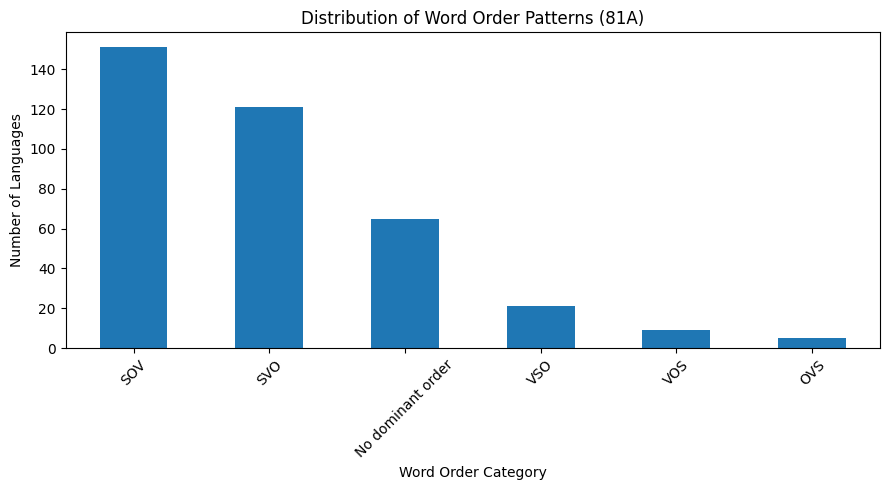

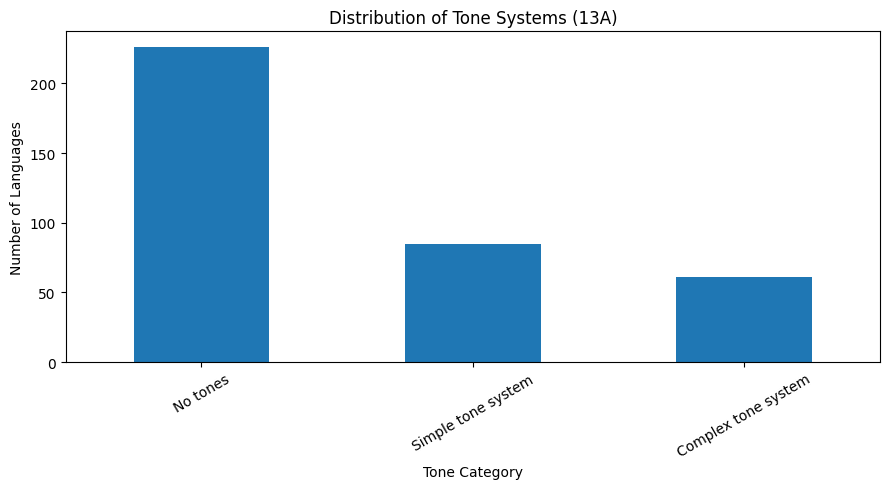

In [28]:
import matplotlib.pyplot as plt

# Plot word order distribution
plt.figure(figsize=(9, 5))

primary_analysis["81A"].value_counts().plot(
    kind="bar",
    rot=45
)

plt.title("Distribution of Word Order Patterns (81A)")
plt.xlabel("Word Order Category")
plt.ylabel("Number of Languages")
plt.tight_layout()
plt.show()


# Plot tone distribution
plt.figure(figsize=(9, 5))

primary_analysis["13A"].value_counts().plot(
    kind="bar",
    rot=30
)

plt.title("Distribution of Tone Systems (13A)")
plt.xlabel("Tone Category")
plt.ylabel("Number of Languages")
plt.tight_layout()
plt.show()

### Interpretation of Word Order and Tone Visualisations

The bar charts provide a visual representation of the category distributions identified in the previous frequency analysis.

For Feature 81A, SOV and SVO are the most prominent word-order patterns, while the remaining categories occur less frequently. OVS is the least represented pattern in the primary dataset.

For Feature 13A, languages without tones form the largest category, followed by languages with simple and complex tone systems.

The visualisations highlight differences in category representation within the dataset. However, they do not establish whether specific word-order patterns are associated with particular tonal systems.

The next analysis will examine the relationship between these two features using a cross-tabulation and a statistical test of association.

### 4.3 Exploring the Relationship Between Word Order and Tone

This section examines the relationship between Feature 81A (Order of Subject, Object and Verb) and Feature 13A (Tone).

A cross-tabulation will be used to compare the frequency of each word-order category across the three tonal categories.

This will help identify which combinations occur most frequently and whether certain word-order patterns appear more commonly alongside particular tonal systems.

The analysis uses the 372 languages in the primary analysis dataset.

In [29]:
# Create a cross-tabulation of word order and tone

word_order_tone_table = pd.crosstab(
    primary_analysis["81A"],
    primary_analysis["13A"]
)

print("Word Order and Tone Cross-Tabulation:")
display(word_order_tone_table)


# Calculate row percentages

word_order_tone_percentages = (
    pd.crosstab(
        primary_analysis["81A"],
        primary_analysis["13A"],
        normalize="index"
    ) * 100
).round(2)

print("\nWord Order and Tone - Row Percentages:")
display(word_order_tone_percentages)

Word Order and Tone Cross-Tabulation:


13A,Complex tone system,No tones,Simple tone system
81A,,,
No dominant order,6,51,8
OVS,0,4,1
SOV,14,101,36
SVO,36,51,34
VOS,1,7,1
VSO,4,12,5



Word Order and Tone - Row Percentages:


13A,Complex tone system,No tones,Simple tone system
81A,,,
No dominant order,9.23,78.46,12.31
OVS,0.00,80.00,20.00
SOV,9.27,66.89,23.84
SVO,29.75,42.15,28.10
VOS,11.11,77.78,11.11
VSO,19.05,57.14,23.81


### Interpretation of Word Order and Tone Cross-Tabulation

The cross-tabulation reveals differences in the distribution of tonal systems across word-order categories.

The most frequent combination is SOV with no tones, representing 101 languages. SOV languages also show a higher proportion of observations without tones (66.89%) compared with SVO languages (42.15%).

SVO languages show a more balanced distribution across the three tonal categories. They also have the highest proportion of complex tone systems among the main word-order categories, at 29.75%.

Less frequent word-order categories, including VOS and OVS, have considerably fewer observations. Their distributions should therefore be interpreted cautiously.

These findings suggest potential relationships between word-order patterns and tonal systems. However, cross-tabulation alone cannot establish whether the observed differences represent statistically significant associations.

A statistical test will be required to investigate this further.

### 4.4 Statistical Test of Association

A Chi-square test of independence will be used to investigate whether word-order patterns (81A) and tonal categories (13A) are statistically associated.

The test compares the observed frequencies in the cross-tabulation with the frequencies that would be expected if the two linguistic features were independent.

The following measures will be examined:

- Chi-square statistic: Measures the difference between observed and expected frequencies.
- P-value: Indicates whether the observed association is statistically significant.
- Degrees of freedom: Represents the degrees of freedom used in the test.
- Expected frequencies: Used to assess whether the assumptions of the Chi-square test are satisfied.

Cramér's V will also be calculated to measure the strength of the association.

The analysis uses the 372 languages in the primary dataset.

In [30]:
from scipy.stats import chi2_contingency
import numpy as np

# Perform the Chi-square test of independence

chi2, p_value, degrees_of_freedom, expected = chi2_contingency(
    word_order_tone_table
)

# Calculate Cramér's V

sample_size = word_order_tone_table.to_numpy().sum()

minimum_dimension = min(word_order_tone_table.shape) - 1

cramers_v = np.sqrt(
    chi2 / (sample_size * minimum_dimension)
)

# Display statistical results

print("Chi-square Test of Independence")
print("-" * 45)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"P-value: {p_value:.6f}")
print(f"Degrees of freedom: {degrees_of_freedom}")
print(f"Cramer's V: {cramers_v:.4f}")

# Assess expected frequency assumptions

expected_values = expected.flatten()

print("\nExpected Frequency Assessment")
print("-" * 45)

print("Minimum expected frequency:",
      round(expected_values.min(), 2))

print("Cells with expected frequency below 5:",
      (expected_values < 5).sum())

print("Percentage of cells below 5:",
      round((expected_values < 5).mean() * 100, 2), "%")

Chi-square Test of Independence
---------------------------------------------
Chi-square statistic: 38.1533
P-value: 0.000036
Degrees of freedom: 10
Cramer's V: 0.2265

Expected Frequency Assessment
---------------------------------------------
Minimum expected frequency: 0.82
Cells with expected frequency below 5: 7
Percentage of cells below 5: 38.89 %


### Interpretation of Initial Chi-square Test

The initial Chi-square test produced a statistic of 38.1533 and a p-value of 0.000036. Cramér's V was calculated as 0.227, suggesting a relatively modest association between word-order patterns and tonal categories.

However, the expected frequency assessment identified seven cells (38.89%) with expected frequencies below five, including a minimum expected frequency of 0.82.

This exceeds the commonly used guideline for the Chi-square approximation. Therefore, the initial p-value should not be interpreted as definitive evidence of a statistically significant association.

A permutation-based test will be performed as an alternative approach to assess the relationship while accounting for the observed category frequencies.

### 4.5 Permutation Test of Independence

A permutation test will be used to further investigate the relationship between word order and tone.

The test randomly rearranges the tonal category labels across languages while preserving the original word-order and tonal category frequencies.

This creates a reference distribution under the assumption that word order and tone are independent.

The observed Chi-square statistic will then be compared with the statistics obtained from the random permutations.

A fixed random seed will be used to make the results reproducible.

In [31]:
# Perform a permutation test of independence

import numpy as np

observed_table = word_order_tone_table.to_numpy()

# Calculate the observed Chi-square statistic
observed_chi2 = chi2

# Extract word-order and tone labels
word_order_labels = primary_analysis["81A"].to_numpy()
tone_labels = primary_analysis["13A"].to_numpy()

# Set up the permutation test
number_of_permutations = 10000
random_generator = np.random.default_rng(42)

permuted_statistics = []

# Randomly shuffle tone labels while keeping word order unchanged
for _ in range(number_of_permutations):

    shuffled_tones = random_generator.permutation(tone_labels)

    shuffled_table = pd.crosstab(
        word_order_labels,
        shuffled_tones
    ).reindex(
        index=word_order_tone_table.index,
        columns=word_order_tone_table.columns,
        fill_value=0
    ).to_numpy()

    expected_table = expected

    permutation_chi2 = np.sum(
        (shuffled_table - expected_table) ** 2 / expected_table
    )

    permuted_statistics.append(permutation_chi2)

# Calculate the permutation p-value
permuted_statistics = np.array(permuted_statistics)

extreme_results = np.sum(
    permuted_statistics >= observed_chi2
)

permutation_p_value = (
    extreme_results + 1
) / (
    number_of_permutations + 1
)

print("Permutation Test Results")
print("-" * 45)

print("Observed Chi-square statistic:",
      round(observed_chi2, 4))

print("Number of permutations:",
      number_of_permutations)

print("Permutations with equal or greater statistic:",
      extreme_results)

print("Permutation p-value:",
      round(permutation_p_value, 6))

Permutation Test Results
---------------------------------------------
Observed Chi-square statistic: 38.1533
Number of permutations: 10000
Permutations with equal or greater statistic: 2
Permutation p-value: 0.0003
